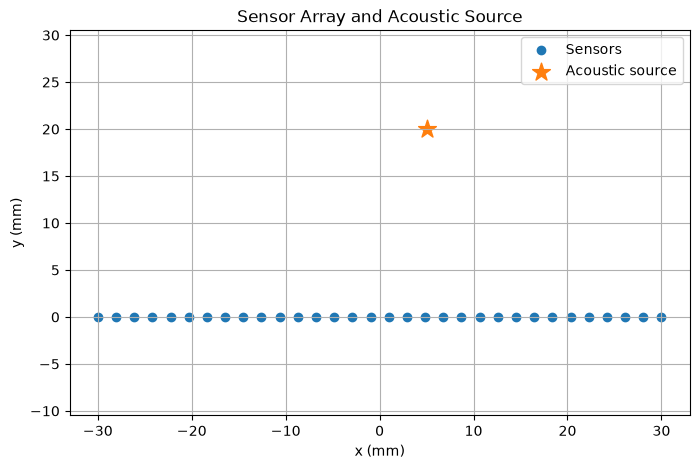

Number of sensors: 32
Sampling frequency: 10.0 MHz


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Create output folder
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Speed of sound (m/s)
c = 1500.0

# Sampling frequency (Hz)
fs = 10e6

# Sensor positions along a straight line (meters)
num_sensors = 32
sensor_x = np.linspace(-0.03, 0.03, num_sensors)
sensor_y = np.zeros(num_sensors)

# Position of the simulated acoustic source (meters)
source_x = 0.005
source_y = 0.020

# Plot sensor positions and source
plt.figure(figsize=(8, 5))

plt.scatter(
    sensor_x * 1000,
    sensor_y * 1000,
    label="Sensors"
)

plt.scatter(
    source_x * 1000,
    source_y * 1000,
    marker="*",
    s=180,
    label="Acoustic source"
)

plt.xlabel("x (mm)")
plt.ylabel("y (mm)")
plt.title("Sensor Array and Acoustic Source")
plt.axis("equal")
plt.grid(True)
plt.legend()

plt.savefig(
    output_dir / "day24_sensor_array.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Number of sensors:", num_sensors)
print("Sampling frequency:", fs / 1e6, "MHz")

In [2]:
# Time axis for the recorded signals
duration = 60e-6  # 60 microseconds
time = np.arange(0, duration, 1 / fs)

# Distance from source to each sensor
distances = np.sqrt(
    (sensor_x - source_x)**2
    + (sensor_y - source_y)**2
)

# Time of arrival at each sensor
arrival_times = distances / c

# Create an artificial pulse for each sensor
signals = np.zeros((num_sensors, len(time)))

pulse_width = 1.5e-6  # seconds

for i in range(num_sensors):
    signals[i] = np.exp(
        -0.5 * ((time - arrival_times[i]) / pulse_width)**2
    )

print("Signal matrix shape:", signals.shape)
print("First sensor arrival time:",
      arrival_times[0] * 1e6, "microseconds")

Signal matrix shape: (32, 600)
First sensor arrival time: 26.874192494328494 microseconds


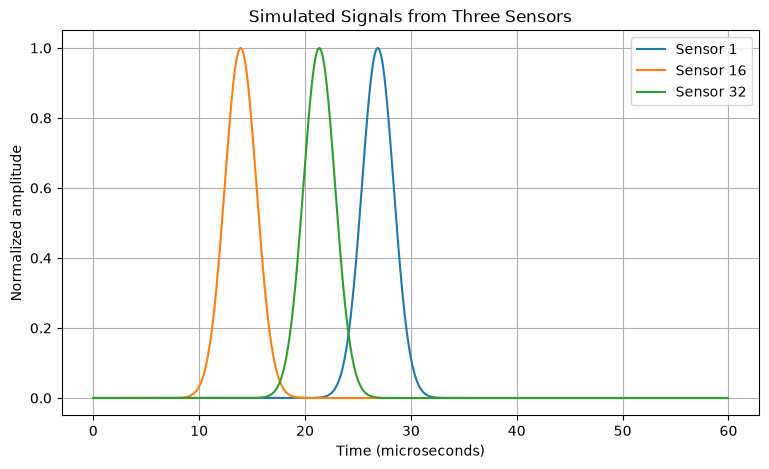

In [3]:
plt.figure(figsize=(9, 5))

selected_sensors = [0, 15, 31]

for i in selected_sensors:
    plt.plot(
        time * 1e6,
        signals[i],
        label=f"Sensor {i + 1}"
    )

plt.xlabel("Time (microseconds)")
plt.ylabel("Normalized amplitude")
plt.title("Simulated Signals from Three Sensors")
plt.grid(True)
plt.legend()

plt.savefig(
    output_dir / "day24_simulated_sensor_signals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [4]:
# Define the image reconstruction grid (meters)
image_size = 100

x_grid = np.linspace(-0.03, 0.03, image_size)
y_grid = np.linspace(0.0, 0.04, image_size)

X, Y = np.meshgrid(x_grid, y_grid)

print("Image grid shape:", X.shape)

Image grid shape: (100, 100)


In [6]:
def delay_and_sum(
    signals,
    time,
    sensor_x,
    sensor_y,
    X,
    Y,
    c
):
    """
    Reconstruct a 2D image using Delay-and-Sum (DAS).

    signals: array of shape (num_sensors, num_time_samples)
    time: time axis in seconds
    sensor_x, sensor_y: sensor coordinates in meters
    X, Y: image grid coordinates in meters
    c: speed of sound in meters/second
    """

    num_sensors = signals.shape[0]

    image = np.zeros(X.shape, dtype=float)

    for i in range(num_sensors):

        # Distance from every image pixel to sensor i
        distance = np.sqrt(
            (X - sensor_x[i])**2
            + (Y - sensor_y[i])**2
        )

        # Predicted travel time
        tof = distance / c

        # Convert time to sample indices
        sample_indices = np.rint(
            (tof - time[0]) / (time[1] - time[0])
        ).astype(int)

        # Only use indices inside the recorded signal
        valid = (
            (sample_indices >= 0)
            & (sample_indices < len(time))
        )

        sensor_contribution = np.zeros(X.shape)

        sensor_contribution[valid] = signals[
            i, sample_indices[valid]
        ]

        # Add this sensor's contribution
        image += sensor_contribution

    return image

In [7]:
print("DAS function is ready!")

DAS function is ready!


In [8]:
reconstructed_image = delay_and_sum(
    signals=signals,
    time=time,
    sensor_x=sensor_x,
    sensor_y=sensor_y,
    X=X,
    Y=Y,
    c=c
)

print("Reconstruction complete!")
print("Image shape:", reconstructed_image.shape)
print("Maximum intensity:", reconstructed_image.max())

Reconstruction complete!
Image shape: (100, 100)
Maximum intensity: 31.893867622002485


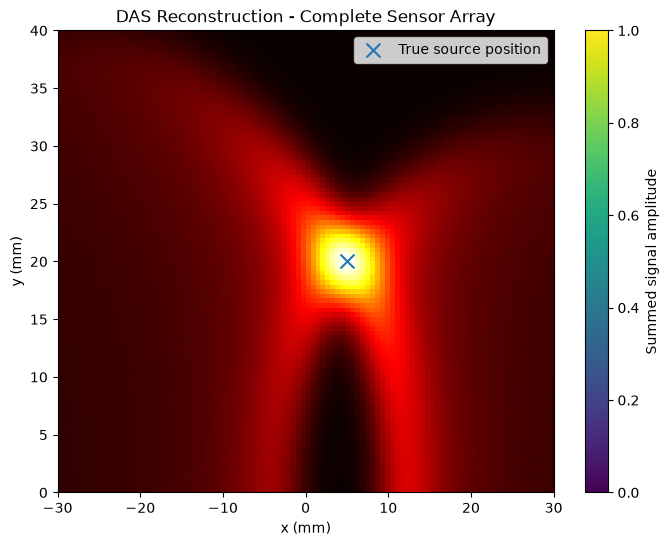

In [9]:
plt.figure(figsize=(8, 6))

plt.imshow(
    reconstructed_image,
    extent=[
        x_grid.min() * 1000,
        x_grid.max() * 1000,
        y_grid.min() * 1000,
        y_grid.max() * 1000
    ],
    origin="lower",
    aspect="auto",
    cmap="hot"
)

plt.scatter(
    [source_x * 1000],
    [source_y * 1000],
    marker="x",
    s=100,
    label="True source position"
)

plt.xlabel("x (mm)")
plt.ylabel("y (mm)")
plt.title("DAS Reconstruction - Complete Sensor Array")
plt.colorbar(label="Summed signal amplitude")
plt.legend()

plt.savefig(
    output_dir / "day24_das_reconstruction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
# Find the brightest pixel in the reconstructed image
max_index = np.unravel_index(
    np.argmax(reconstructed_image),
    reconstructed_image.shape
)

# Estimated source position
estimated_x = X[max_index]
estimated_y = Y[max_index]

# Calculate localization error
error = np.sqrt(
    (estimated_x - source_x)**2
    + (estimated_y - source_y)**2
)

print(f"True source: ({source_x*1000:.2f}, {source_y*1000:.2f}) mm")
print(f"Estimated source: ({estimated_x*1000:.2f}, {estimated_y*1000:.2f}) mm")
print(f"Localization error: {error*1000:.2f} mm")

True source: (5.00, 20.00) mm
Estimated source: (5.15, 19.80) mm
Localization error: 0.25 mm


In [11]:
import json

results = {
    "num_sensors": int(num_sensors),
    "sampling_frequency_hz": float(fs),
    "image_grid": list(reconstructed_image.shape),
    "true_source_mm": [
        float(source_x * 1000),
        float(source_y * 1000)
    ],
    "estimated_source_mm": [
        float(estimated_x * 1000),
        float(estimated_y * 1000)
    ],
    "localization_error_mm": float(error * 1000)
}

results_path = output_dir / "day24_das_results.json"

with open(results_path, "w") as file:
    json.dump(results, file, indent=4)

print("Results saved to:", results_path)

Results saved to: ..\outputs\day24_das_results.json
